# Olist E-commerce Analysis with PySpark

Customer geography, geolocation quality, purchase amounts, and delivery experience.

Originally developed for a data science course at the University of Mississippi.

## Questions

1. How are customer records distributed across states and regions?
2. Can ZIP-prefix median coordinates reduce the impact of geographic outliers?
3. Do mean order payment amounts differ between São Paulo and Rio de Janeiro **states**?
4. How is delivery time associated with review score?

## Run status and setup

Executed in Databricks; the exported notebook contains saved results and charts with no saved error outputs. The findings below reflect that run, reviewed on October 5, 2026.

Use a Databricks Python notebook with Spark, a readable Unity Catalog volume, and NumPy, pandas, SciPy, Matplotlib, and psutil available. Download and extract the [Olist dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), upload the five CSVs listed in the README, update `DATA_DIR`, then run all cells in order. This notebook uses Databricks `display` and `dbutils`.

## Findings

- 99,441 distinct customer IDs and 96,096 distinct customer-unique IDs.
- 1,000,163 geolocation records covering 19,015 ZIP prefixes.
- 40 geolocation rows outside the chosen bounding box with a one-degree margin; seven ZIP prefixes had median coordinates outside the unexpanded box.
- 576 of 1,000,134 retained geolocation rows were more than 200 km from their ZIP-prefix median (about 0.0576%). These are row counts, not counts of distinct ZIP prefixes.
- Mean summed payment per order: São Paulo 143.69 and Rio de Janeiro 166.85; SP − RJ = −23.16. Welch t-test: t ≈ −9.83, p ≈ 9.81 × 10⁻²³.
- Delivery-time/review-score correlation: r ≈ −0.334.

Both permutation tests returned p ≈ 0.0002 using 5,000 random permutations and the plus-one correction. No sampled permutation was as extreme as the observed statistic. The CSV reader handles quoted multiline records.


In [0]:
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.functions import col
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

spark = SparkSession.builder.appName("OlistEcommerceAnalysis").getOrCreate()
DATA_DIR = "/Volumes/workspace/default/files/olist"  # Change to your volume.
SEED = 42
N_PERMUTATIONS = 5000

def read_olist(filename):
    # Olist review comments can contain quoted commas, quotes, and newlines.
    return (spark.read.option("header", True)
            .option("inferSchema", True)
            .option("multiLine", True)
            .option("quote", '"').option("escape", '"')
            .csv(f"{DATA_DIR.rstrip('/')}/{filename}"))


## 1. Data access

Inspect the volume and load customer records.

In [0]:
display(dbutils.fs.ls(DATA_DIR))

path,name,size,modificationTime
dbfs:/Volumes/workspace/default/files/olist/olist_customers_dataset.csv,olist_customers_dataset.csv,9033957,1776933829000
dbfs:/Volumes/workspace/default/files/olist/olist_geolocation_dataset.csv,olist_geolocation_dataset.csv,61273883,1776933941000
dbfs:/Volumes/workspace/default/files/olist/olist_order_items_dataset.csv,olist_order_items_dataset.csv,15438671,1776933867000
dbfs:/Volumes/workspace/default/files/olist/olist_order_payments_dataset.csv,olist_order_payments_dataset.csv,5777138,1776933805000
dbfs:/Volumes/workspace/default/files/olist/olist_order_reviews_dataset.csv,olist_order_reviews_dataset.csv,14451670,1776933863000
dbfs:/Volumes/workspace/default/files/olist/olist_orders_dataset.csv,olist_orders_dataset.csv,17654914,1776933875000
dbfs:/Volumes/workspace/default/files/olist/olist_products_dataset.csv,olist_products_dataset.csv,2379446,1776933775000
dbfs:/Volumes/workspace/default/files/olist/olist_sellers_dataset.csv,olist_sellers_dataset.csv,174703,1776933751000
dbfs:/Volumes/workspace/default/files/olist/product_category_name_translation.csv,product_category_name_translation.csv,2613,1776933749000


In [0]:
df_customers = read_olist("olist_customers_dataset.csv")

display(df_customers.limit(10))

customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC
fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,4534,sao paulo,SP
5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,timoteo,MG
5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR
4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,belo horizonte,MG


### File sizes

Disk size is a first sizing check; in-memory DataFrames and temporary conversions can use more memory.

In [0]:
files = dbutils.fs.ls(DATA_DIR)

for f in files:
    print(f.name, f.size)


olist_customers_dataset.csv 9033957
olist_geolocation_dataset.csv 61273883
olist_order_items_dataset.csv 15438671
olist_order_payments_dataset.csv 5777138
olist_order_reviews_dataset.csv 14451670
olist_orders_dataset.csv 17654914
olist_products_dataset.csv 2379446
olist_sellers_dataset.csv 174703
product_category_name_translation.csv 2613


In [0]:
total_size = 0

for f in files:
    size_mb = f.size / (1024 * 1024)
    total_size += size_mb
    print(f"{f.name}: {size_mb:.2f} MB")

print(f"\nTotal size: {total_size:.2f} MB")

olist_customers_dataset.csv: 8.62 MB
olist_geolocation_dataset.csv: 58.44 MB
olist_order_items_dataset.csv: 14.72 MB
olist_order_payments_dataset.csv: 5.51 MB
olist_order_reviews_dataset.csv: 13.78 MB
olist_orders_dataset.csv: 16.84 MB
olist_products_dataset.csv: 2.27 MB
olist_sellers_dataset.csv: 0.17 MB
product_category_name_translation.csv: 0.00 MB

Total size: 120.34 MB


### Customer identifiers

`customer_id` links a customer record to an order. `customer_unique_id` identifies returning customers across orders. State and region charts below count records, not distinct people.

In [0]:
df_customers.selectExpr(
    "count(distinct customer_id) as unique_customer_id",
    "count(distinct customer_unique_id) as unique_customer_unique_id"
).show()

+------------------+-------------------------+
|unique_customer_id|unique_customer_unique_id|
+------------------+-------------------------+
|             99441|                    96096|
+------------------+-------------------------+



### Missing-value screening

Check nulls, empty strings, and placeholder strings. Zero is checked only for ZIP prefixes; zero latitude or longitude is not automatically missing. This is a screening rule, not proof of complete data quality.

In [0]:
from functools import reduce
from pyspark.sql.functions import lower, trim

def find_missing_rows(df):
    conditions = []
    for field in df.schema.fields:
        name = field.name
        cond = col(name).isNull()
        if name.endswith("zip_code_prefix"):
            cond = cond | (col(name) == 0)
        if field.dataType.simpleString() == "string":
            cond = cond | lower(trim(col(name))).isin("", "na", "n/a", "none")
        conditions.append(cond)
    return df.filter(reduce(lambda a, b: a | b, conditions))


In [0]:
missing_df = find_missing_rows(df_customers)

display(missing_df.limit(10))
print("Number of rows with missing/invalid data:", missing_df.count())

customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state


Number of rows with missing/invalid data: 0


### State coverage

In [0]:
print("Number of unique states:", df_customers.select("customer_state").distinct().count())
display(df_customers.select("customer_state").distinct().orderBy("customer_state"))

Number of unique states: 27


customer_state
AC
AL
AM
AP
BA
CE
DF
ES
GO
MA


### Customer records by state

Aggregate with Spark before collecting the small result for plotting.

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

# Count customer records per state in Spark
state_counts = (
    df_customers
    .groupBy("customer_state")
    .count()
    .orderBy("customer_state")
)

display(state_counts)

customer_state,count
AC,81
AL,413
AM,148
AP,68
BA,3380
CE,1336
DF,2140
ES,2033
GO,2020
MA,747


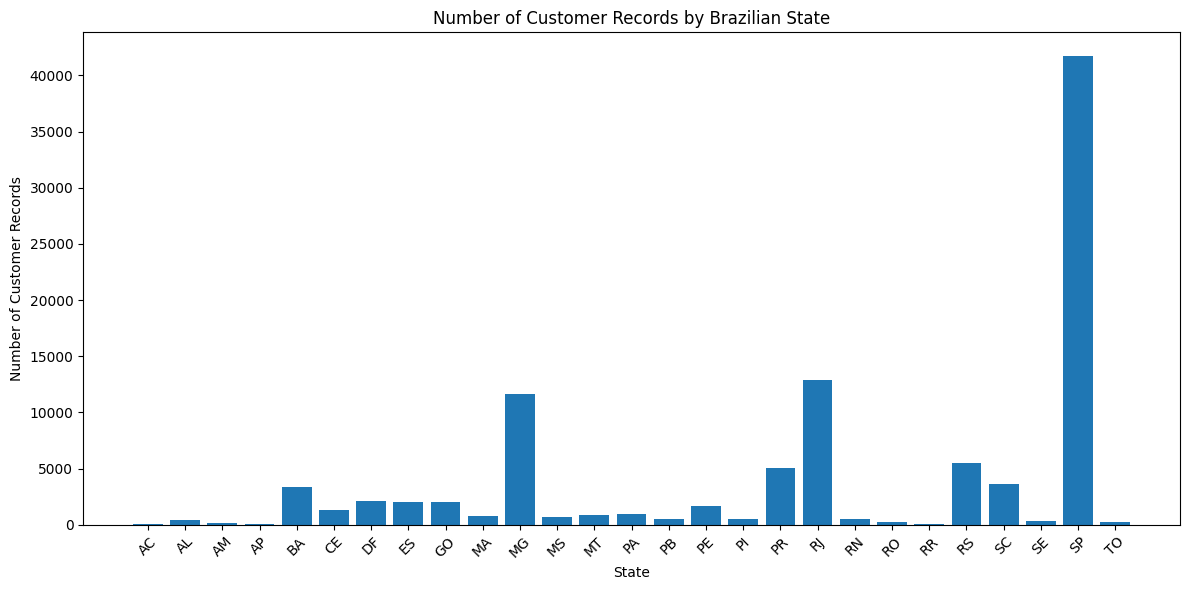

In [0]:
state_counts_pd = state_counts.toPandas()

plt.figure(figsize=(12, 6))
plt.bar(state_counts_pd["customer_state"], state_counts_pd["count"])
plt.xlabel("State")
plt.ylabel("Number of Customer Records")
plt.title("Number of Customer Records by Brazilian State")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Customer records by region

Create a derived DataFrame with region labels; the original Spark DataFrame is unchanged.

In [0]:
from pyspark.sql.functions import col, when

df_customers_region = (
    df_customers
    .withColumn(
        "region",
        when(col("customer_state").isin("ES", "MG", "RJ", "SP"), "Southeast")
        .when(col("customer_state").isin("PR", "SC", "RS"), "South")
        .when(col("customer_state").isin("AC", "AP", "AM", "PA", "RO", "RR", "TO"), "North")
        .when(col("customer_state").isin("AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"), "Northeast")
        .when(col("customer_state").isin("GO", "MT", "MS", "DF"), "Central-West")
        .otherwise("Unknown")
    )
)

display(df_customers_region.limit(10))

customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,region
06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP,Southeast
18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP,Southeast
4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP,Southeast
b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP,Southeast
4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP,Southeast
879864dab9bc3047522c92c82e1212b8,4c93744516667ad3b8f1fb645a3116a4,89254,jaragua do sul,SC,South
fd826e7cf63160e536e0908c76c3f441,addec96d2e059c80c30fe6871d30d177,4534,sao paulo,SP,Southeast
5e274e7a0c3809e14aba7ad5aae0d407,57b2a98a409812fe9618067b6b8ebe4f,35182,timoteo,MG,Southeast
5adf08e34b2e993982a47070956c5c65,1175e95fb47ddff9de6b2b06188f7e0d,81560,curitiba,PR,South
4b7139f34592b3a31687243a302fa75b,9afe194fb833f79e300e37e580171f22,30575,belo horizonte,MG,Southeast


In [0]:
print("Unclassified customer records:", df_customers_region.filter(col("region") == "Unknown").count())


Unclassified customer records: 0


In [0]:
region_counts = (
    df_customers_region
    .groupBy("region")
    .count()
    .orderBy("region")
)

display(region_counts)

region,count
Central-West,5782
North,1851
Northeast,9394
South,14148
Southeast,68266


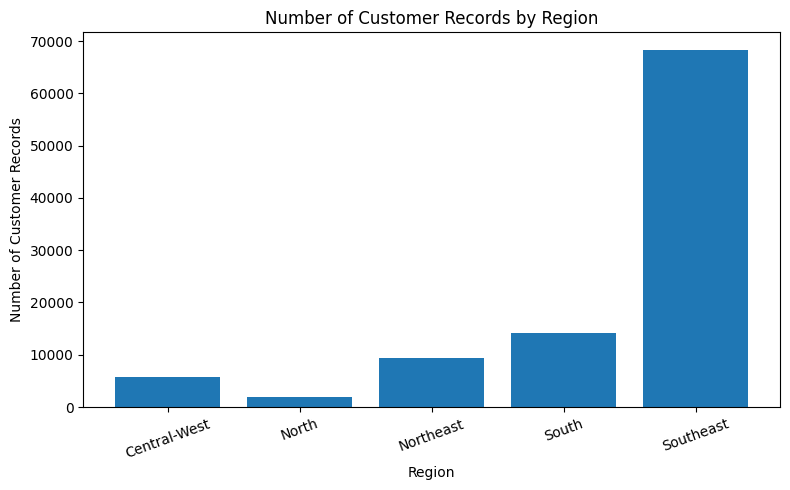

In [0]:
region_counts_pd = region_counts.toPandas()

plt.figure(figsize=(8, 5))
plt.bar(region_counts_pd["region"], region_counts_pd["count"])
plt.xlabel("Region")
plt.ylabel("Number of Customer Records")
plt.title("Number of Customer Records by Region")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 2. Geolocation quality

Multiple coordinate records can share the same ZIP prefix. Retain raw observations and create separate derived views.

In [0]:
geo_df = read_olist("olist_geolocation_dataset.csv")

display(geo_df.limit(10))

geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
1037,-23.54562128115268,-46.63929204800168,sao paulo,SP
1046,-23.546081127035535,-46.64482029837157,sao paulo,SP
1046,-23.54612896641469,-46.64295148361138,sao paulo,SP
1041,-23.5443921648681,-46.63949930627844,sao paulo,SP
1035,-23.541577961711493,-46.64160722329613,sao paulo,SP
1012,-23.547762303364266,-46.63536053788448,são paulo,SP
1047,-23.546273112412678,-46.64122516971552,sao paulo,SP
1013,-23.546923208436723,-46.6342636964915,sao paulo,SP
1029,-23.543769055769133,-46.63427784085132,sao paulo,SP
1011,-23.547639550320632,-46.63603162315495,sao paulo,SP


### Row counts and ZIP-prefix coverage

In [0]:
total_rows = geo_df.count()
print("Total rows:", total_rows)

Total rows: 1000163


In [0]:
distinct_zips = geo_df.select("geolocation_zip_code_prefix").distinct().count()
print("Distinct zip prefixes:", distinct_zips)

Distinct zip prefixes: 19015


### Missing-value screening

In [0]:
geo_missing_df = find_missing_rows(geo_df)

display(geo_missing_df.limit(10))
print("Number of rows with missing or suspicious data:", geo_missing_df.count())

geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state


Number of rows with missing or suspicious data: 0


### Estimate driver memory use

A small sample provides a rough per-row estimate. It excludes conversion overhead and is not a guarantee that collecting the full dataset is safe. Geographic plotting below uses this sample.

In [0]:
import psutil

# 1) take a small sample from the Spark DataFrame
sample_fraction = 0.01   # 1%
geo_sample = geo_df.sample(withReplacement=False, fraction=sample_fraction, seed=42)

# 2) convert sample to pandas
geo_sample_pd = geo_sample.toPandas()

# 3) measure sample memory usage
sample_memory_bytes = geo_sample_pd.memory_usage(deep=True).sum()
sample_memory_mb = sample_memory_bytes / (1024**2)

# 4) estimate full dataset memory from the sample
sample_rows = len(geo_sample_pd)
full_rows = geo_df.count()
if sample_rows == 0:
    raise ValueError("Empty memory-estimation sample; increase sample_fraction.")
estimated_full_bytes = sample_memory_bytes / sample_rows * full_rows
estimated_full_mb = estimated_full_bytes / (1024**2)
estimated_full_gb = estimated_full_bytes / (1024**3)

# also helpful: compare row counts
sample_rows = len(geo_sample_pd)
full_rows = geo_df.count()

# 5) inspect driver memory
vm = psutil.virtual_memory()
total_mem_gb = vm.total / (1024**3)
available_mem_gb = vm.available / (1024**3)

print(f"Sample fraction: {sample_fraction}")
print(f"Sample rows: {sample_rows}")
print(f"Full rows: {full_rows}")
print(f"Sample memory usage: {sample_memory_mb:.2f} MB")
print(f"Estimated full dataset memory: {estimated_full_mb:.2f} MB ({estimated_full_gb:.2f} GB)")
print(f"Driver total memory: {total_mem_gb:.2f} GB")
print(f"Driver available memory: {available_mem_gb:.2f} GB")

Sample fraction: 0.01
Sample rows: 9965
Full rows: 1000163
Sample memory usage: 1.25 MB
Estimated full dataset memory: 125.65 MB (0.12 GB)
Driver total memory: 15.28 GB
Driver available memory: 6.36 GB


### Geographic screening

Use an approximate rectangular boundary from the coursework, with a one-degree plotting margin. This does not establish whether a point lies inside the national border and can flag legitimate locations outside the chosen rectangle. Treat flags as candidates for review.

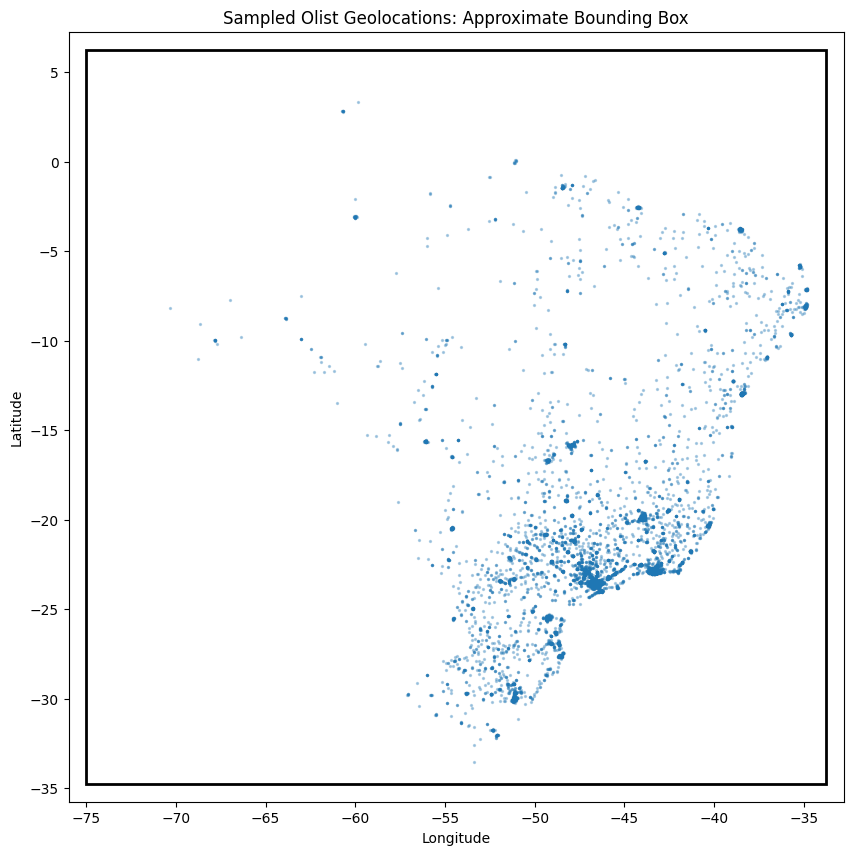

In [0]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Reuse the small seeded sample for plotting.
geo_pd = geo_sample_pd

# Brazil bounding box in decimal degrees
brazil_min_lat = -33.7508
brazil_max_lat = 5.2694
brazil_min_lng = -73.9831
brazil_max_lng = -34.7931

# 1-degree margin
margin = 1.0
plot_min_lat = brazil_min_lat - margin
plot_max_lat = brazil_max_lat + margin
plot_min_lng = brazil_min_lng - margin
plot_max_lng = brazil_max_lng + margin

plt.figure(figsize=(10, 10))
plt.scatter(
    geo_pd["geolocation_lng"],
    geo_pd["geolocation_lat"],
    s=2,
    alpha=0.3
)

ax = plt.gca()
rect = patches.Rectangle(
    (plot_min_lng, plot_min_lat),
    plot_max_lng - plot_min_lng,
    plot_max_lat - plot_min_lat,
    linewidth=2,
    fill=False
)
ax.add_patch(rect)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Sampled Olist Geolocations: Approximate Bounding Box")
plt.xlim(plot_min_lng - 1, plot_max_lng + 1)
plt.ylim(plot_min_lat - 1, plot_max_lat + 1)
plt.show()

### Rows outside the expanded rectangle

In [0]:
from pyspark.sql.functions import col

outside_margin_df = geo_df.filter(
    (col("geolocation_lat") < plot_min_lat) |
    (col("geolocation_lat") > plot_max_lat) |
    (col("geolocation_lng") < plot_min_lng) |
    (col("geolocation_lng") > plot_max_lng)
)

outside_margin_count = outside_margin_df.count()
print("Rows outside the 1-degree-margin bounding box:", outside_margin_count)

display(outside_margin_df.limit(20))

Rows outside the 1-degree-margin bounding box: 40


geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
18243,28.008978338034268,-15.536867177679131,bom retiro da esperanca,SP
28165,41.61405150610495,-8.411675312504059,vila nova de campos,RJ
28155,42.43928591592116,13.82021409761152,santa maria,RJ
28333,38.38167205114709,-6.328200272094753,raposo,RJ
28595,43.68496096631822,-7.411080413859842,portela,RJ
29654,29.40925222930908,-98.48412074808029,santo antônio do canaã,ES
29654,21.65754744931478,-101.46676644931476,santo antonio do canaa,ES
35179,25.995202881053306,-98.07854439291536,santana do paraíso,MG
35179,25.995244980240102,-98.07853309801159,santana do paraiso,MG
45936,38.3239386880374,-6.775035344018704,itabatan,BA


### Distinct city/state labels

Spelling variants can create multiple labels for one city, so this is not an authoritative count of cities.

In [0]:
city_state_df = geo_df.select("geolocation_city", "geolocation_state").distinct()

num_city_state_pairs = city_state_df.count()
print("Number of distinct city-state pairs:", num_city_state_pairs)

display(city_state_df.limit(20))

Number of distinct city-state pairs: 8463


geolocation_city,geolocation_state
sao paulo,SP
jandira,SP
jundiaí,SP
sao jose dos campos,SP
sa£o paulo,SP
sao bernardo do campo,SP
santana de parnaiba,SP
itapevi,SP
osasco,SP
sao paulo,AC


### Median coordinates by ZIP prefix

Use Spark approximate medians to reduce the effect of extreme coordinates. Median latitude and longitude are computed separately and need not identify an actual address.

In [0]:
#step 1
from pyspark.sql import functions as F

geo_df_median = (
    geo_df
    .groupBy("geolocation_zip_code_prefix")
    .agg(
        F.expr("percentile_approx(geolocation_lat, 0.5)").alias("median_lat"),
        F.expr("percentile_approx(geolocation_lng, 0.5)").alias("median_lng"),
        F.count("*").alias("row_count")
    )
)

display(geo_df_median.limit(10))

geolocation_zip_code_prefix,median_lat,median_lng,row_count
1035,-23.540983825979165,-46.64256855760085,39
1156,-23.5295707260661,-46.665109917017695,94
1303,-23.54919071579432,-46.64818240521669,166
1441,-23.56496279788524,-46.67630075455378,21
1450,-23.575921313347585,-46.685162032200324,29
1447,-23.572517679150593,-46.67880126395058,14
1518,-23.558930444630374,-46.62292373757862,23
2046,-23.491579169859758,-46.61162269747246,29
2265,-23.475049354434713,-46.592039624617684,35
2257,-23.472938598389987,-46.583483541760316,37


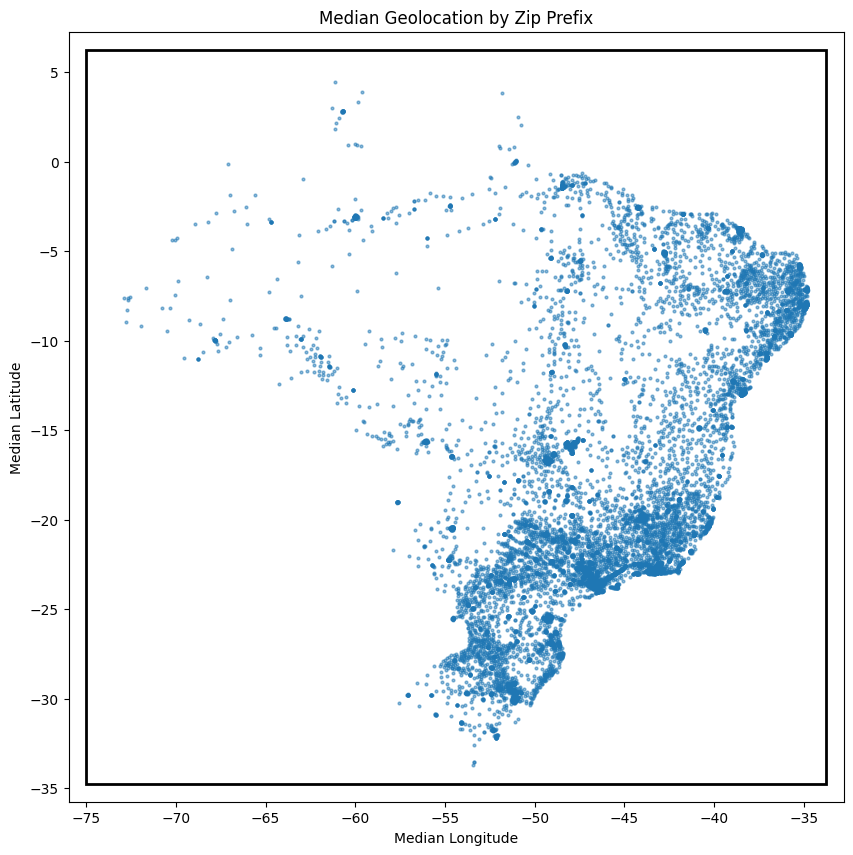

In [0]:
#step 2

geo_median_pd = geo_df_median.toPandas()

plt.figure(figsize=(10, 10))
plt.scatter(
    geo_median_pd["median_lng"],
    geo_median_pd["median_lat"],
    s=4,
    alpha=0.5
)

ax = plt.gca()
rect = patches.Rectangle(
    (plot_min_lng, plot_min_lat),
    plot_max_lng - plot_min_lng,
    plot_max_lat - plot_min_lat,
    linewidth=2,
    fill=False
)
ax.add_patch(rect)

plt.xlabel("Median Longitude")
plt.ylabel("Median Latitude")
plt.title("Median Geolocation by Zip Prefix")
plt.xlim(plot_min_lng - 1, plot_max_lng + 1)
plt.ylim(plot_min_lat - 1, plot_max_lat + 1)
plt.show()


### Inspect ZIP prefixes with medians outside the rectangle

In [0]:
median_outside_df = geo_df_median.filter(
    (col("median_lat") < brazil_min_lat) |
    (col("median_lat") > brazil_max_lat) |
    (col("median_lng") < brazil_min_lng) |
    (col("median_lng") > brazil_max_lng)
)

print("Zip prefixes whose median falls outside the chosen rectangle:", median_outside_df.count())
display(median_outside_df)

Zip prefixes whose median falls outside the chosen rectangle: 7


geolocation_zip_code_prefix,median_lat,median_lng,row_count
53990,-3.848319000000004,-32.413367452152805,11
18243,28.008978338034268,-15.536867177679131,1
95130,14.585072541779617,121.10539381057764,1
83252,42.18400274298598,-8.723762147513938,2
78131,38.81681628638297,-9.394624510957431,1
68275,41.14620290949943,-8.57785501800488,9
29654,-19.823679852987716,-98.48412074808029,4


In [0]:
#step 4

bad_zip_df = geo_df.join(
    median_outside_df.select("geolocation_zip_code_prefix"),
    on="geolocation_zip_code_prefix",
    how="inner"
)

display(bad_zip_df.orderBy("geolocation_zip_code_prefix"))

geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
18243,28.008978338034268,-15.536867177679131,bom retiro da esperanca,SP
29654,-19.823679852987716,-40.65547380047472,santo antonio do canaa,ES
29654,29.40925222930908,-98.48412074808029,santo antônio do canaã,ES
29654,21.65754744931478,-101.46676644931476,santo antonio do canaa,ES
29654,-19.824999999999932,-40.654439999999965,santo antonio do canaa,ES
53990,-3.853091999999947,-32.423524999999955,fernando de noronha,PE
53990,-3.8440799999999915,-32.405985,fernando de noronha,PE
53990,-3.853091999999947,-32.423524999999955,fernando de noronha,PE
53990,-3.8440799999999915,-32.405985,fernando de noronha,PE
53990,-3.8469299891113327,-32.415820786968744,fernando de noronha,PE


In [0]:
#step 5
bad_city_counts = (
    bad_zip_df
    .select("geolocation_city", "geolocation_state", "geolocation_zip_code_prefix")
    .distinct()
    .groupBy("geolocation_city", "geolocation_state")
    .count()
    .orderBy(F.desc("count"))
)

display(bad_city_counts)

geolocation_city,geolocation_state,count
ilha dos valadares,PR,1
fernando de noronha,PE,1
bom retiro da esperanca,SP,1
oriximina,PA,1
porto trombetas,PA,1
santo antônio do canaã,ES,1
santa lucia do piai,RS,1
santo antonio do canaa,ES,1
varzea grande,MT,1


In [0]:
single_row_bad_count = median_outside_df.filter(col("row_count") == 1).count()
total_bad_count = median_outside_df.count()

print("Bad median zip prefixes with only one row:", single_row_bad_count)
print("Total bad median zip prefixes:", total_bad_count)



Bad median zip prefixes with only one row: 3
Total bad median zip prefixes: 7


### Distance from ZIP-prefix medians

Keep a derived view whose median coordinates pass the rectangular screen. Compute great-circle distance with the haversine formula. These filters are exploratory assumptions, not verified address corrections.

In [0]:
geo_df_median_valid = geo_df_median.filter(
    (col("median_lat") >= brazil_min_lat) &
    (col("median_lat") <= brazil_max_lat) &
    (col("median_lng") >= brazil_min_lng) &
    (col("median_lng") <= brazil_max_lng)
)

In [0]:
geo_df_both = geo_df.join(
    geo_df_median_valid.select("geolocation_zip_code_prefix", "median_lat", "median_lng"),
    on="geolocation_zip_code_prefix",
    how="inner"
)

display(geo_df_both.limit(10))

geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state,median_lat,median_lng
1037,-23.54562128115268,-46.63929204800168,sao paulo,SP,-23.54562128115268,-46.63929204800168
1046,-23.546081127035535,-46.64482029837157,sao paulo,SP,-23.546081127035535,-46.64381018541167
1046,-23.54612896641469,-46.64295148361138,sao paulo,SP,-23.546081127035535,-46.64381018541167
1041,-23.5443921648681,-46.63949930627844,sao paulo,SP,-23.543712849558617,-46.6402632336835
1035,-23.541577961711493,-46.64160722329613,sao paulo,SP,-23.540983825979165,-46.64256855760085
1012,-23.547762303364266,-46.63536053788448,são paulo,SP,-23.547742270615682,-46.63488111172018
1047,-23.546273112412678,-46.64122516971552,sao paulo,SP,-23.546273112412678,-46.64122516971552
1013,-23.546923208436723,-46.6342636964915,sao paulo,SP,-23.547307871775626,-46.63423875382303
1029,-23.543769055769133,-46.63427784085132,sao paulo,SP,-23.54130569969415,-46.63302994561133
1011,-23.547639550320632,-46.63603162315495,sao paulo,SP,-23.546690486964888,-46.635446958807194


In [0]:
from pyspark.sql.functions import radians, sin, cos, asin, sqrt, lit

R = 6371.0  # Earth radius in km

geo_df_both = (
    geo_df_both
    .withColumn("lat1", radians(col("geolocation_lat")))
    .withColumn("lng1", radians(col("geolocation_lng")))
    .withColumn("lat2", radians(col("median_lat")))
    .withColumn("lng2", radians(col("median_lng")))
    .withColumn("dlat", col("lat2") - col("lat1"))
    .withColumn("dlng", col("lng2") - col("lng1"))
    .withColumn(
        "a",
        sin(col("dlat") / 2) ** 2 +
        cos(col("lat1")) * cos(col("lat2")) * sin(col("dlng") / 2) ** 2
    )
    .withColumn("distance_km", lit(2 * R) * asin(sqrt(F.least(lit(1.0), F.greatest(lit(0.0), col("a"))))))
)

In [0]:
geo_far_df = geo_df_both.filter(col("distance_km") > 200)

far_count = geo_far_df.count()
total_count = geo_df_both.count()
far_fraction = far_count / total_count if total_count else float("nan")

print("Rows more than 200 km from median:", far_count)
print("Total rows considered:", total_count)
print("Fraction more than 200 km from median:", far_fraction)

display(geo_far_df.select(
    "geolocation_zip_code_prefix",
    "geolocation_city",
    "geolocation_state",
    "geolocation_lat",
    "geolocation_lng",
    "median_lat",
    "median_lng",
    "distance_km"
).orderBy(F.desc("distance_km")))

Rows more than 200 km from median: 576
Total rows considered: 1000134
Fraction more than 200 km from median: 0.0005759228263412702


geolocation_zip_code_prefix,geolocation_city,geolocation_state,geolocation_lat,geolocation_lng,median_lat,median_lng,distance_km
57319,pau d'arco,AL,45.06593318269697,9.341527629906514,-23.258223635207305,-47.307429999459416,9515.206092048114
28155,santa maria,RJ,42.43928591592116,13.82021409761152,-21.7559355150009,-43.37912434176968,9233.555211588302
28165,vila nova de campos,RJ,41.61405150610495,-8.411675312504059,-24.576786075795262,-51.212135441020564,8577.050689399024
28595,portela,RJ,43.68496096631822,-7.411080413859842,-21.635416978581294,-41.993412339594215,8074.5357716569215
83810,areia branca dos assis,PR,39.057629417004364,-9.400036925109038,-22.678096897080774,-49.36582999999996,8024.961938185446
35179,santana do paraiso,MG,25.995244980240102,-98.07853309801159,-19.38620780146814,-42.54867999999993,7835.309912175764
35179,santana do paraíso,MG,25.995202881053306,-98.07854439291536,-19.38620780146814,-42.54867999999993,7835.308199421869
28333,raposo,RJ,38.38167205114709,-6.328200272094753,-21.09794983470912,-42.112809922459775,7594.370864603374
68379,castelo dos sonhos,PA,38.71312760878105,-9.135741391218955,-20.615002173707744,-41.20606551884209,7395.003519775832
45936,itabatan,BA,38.3239386880374,-6.775035344018704,-17.999945292956085,-39.863064655227475,7150.949429368056


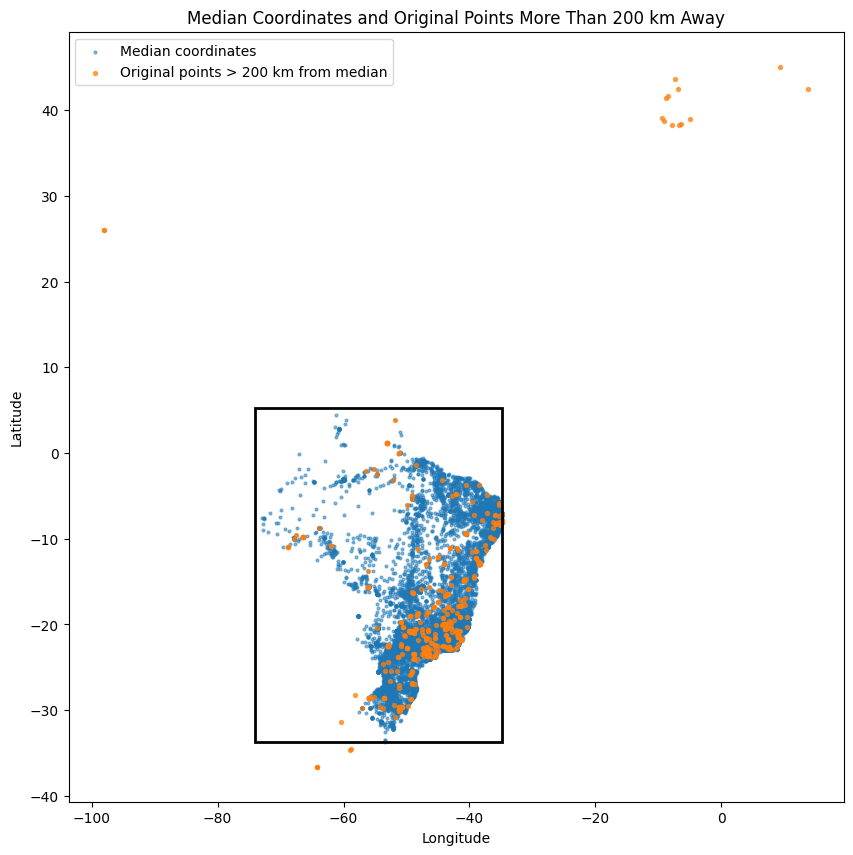

In [0]:
median_pd = geo_df_median_valid.toPandas()
far_pd = geo_far_df.toPandas()

plt.figure(figsize=(10, 10))

plt.scatter(
    median_pd["median_lng"],
    median_pd["median_lat"],
    s=4,
    alpha=0.5,
    label="Median coordinates"
)

plt.scatter(
    far_pd["geolocation_lng"],
    far_pd["geolocation_lat"],
    s=8,
    alpha=0.7,
    label="Original points > 200 km from median"
)

ax = plt.gca()
rect = patches.Rectangle(
    (brazil_min_lng, brazil_min_lat),
    brazil_max_lng - brazil_min_lng,
    brazil_max_lat - brazil_min_lat,
    linewidth=2,
    fill=False
)
ax.add_patch(rect)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Median Coordinates and Original Points More Than 200 km Away")
plt.legend()
plt.show()

## 3. Order payments: São Paulo versus Rio de Janeiro

Sum payment records per order before joining customers. Compare **states**, not cities. All order statuses are retained; summed payment value is not net revenue or profit. Repeated buyers can introduce dependence across orders.

Welch test: H₀: equal state mean payment amounts; H₁: different means. The test allows unequal variances but assumes independent observations.

In [0]:
from pyspark.sql import functions as F

# load needed tables if not already loaded
orders_df = read_olist("olist_orders_dataset.csv")
payments_df = read_olist("olist_order_payments_dataset.csv")
customers_df = read_olist("olist_customers_dataset.csv")

# one total purchase amount per order
order_payments_df = (
    payments_df
    .groupBy("order_id")
    .agg(F.sum("payment_value").alias("total_purchase_amount"))
)

# join to customers through orders
purchase_state_df = (
    orders_df
    .join(customers_df, on="customer_id", how="inner")
    .join(order_payments_df, on="order_id", how="inner")
    .select("order_id", "customer_state", "total_purchase_amount")
)

display(purchase_state_df.limit(10))

order_id,customer_state,total_purchase_amount
e481f51cbdc54678b7cc49136f2d6af7,SP,38.71
53cdb2fc8bc7dce0b6741e2150273451,BA,141.46
47770eb9100c2d0c44946d9cf07ec65d,GO,179.12
949d5b44dbf5de918fe9c16f97b45f8a,RN,72.2
ad21c59c0840e6cb83a9ceb5573f8159,SP,28.62
a4591c265e18cb1dcee52889e2d8acc3,PR,175.26
136cce7faa42fdb2cefd53fdc79a6098,RS,65.95
6514b8ad8028c9f2cc2374ded245783f,RJ,75.16
76c6e866289321a7c93b82b54852dc33,RS,35.95
e69bfb5eb88e0ed6a785585b27e16dbf,SP,169.76


In [0]:
sp_rj_df = purchase_state_df.filter(F.col("customer_state").isin("SP", "RJ"))

sp_rj_pd = sp_rj_df.toPandas()

sp_amounts = sp_rj_pd.loc[sp_rj_pd["customer_state"] == "SP", "total_purchase_amount"]
rj_amounts = sp_rj_pd.loc[sp_rj_pd["customer_state"] == "RJ", "total_purchase_amount"]

print("SP orders:", len(sp_amounts))
print("RJ orders:", len(rj_amounts))
print("SP mean:", sp_amounts.mean())
print("RJ mean:", rj_amounts.mean())

SP orders: 41745
RJ orders: 12852
SP mean: 143.68731488801055
RJ mean: 166.85182773109244


In [0]:
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(sp_amounts, rj_amounts, equal_var=False)

print("Welch t-test statistic:", t_stat)
print("p-value:", p_value)
print("Observed mean difference (SP - RJ):", sp_amounts.mean() - rj_amounts.mean())

Welch t-test statistic: -9.827118638256561
p-value: 9.81202669482346e-23
Observed mean difference (SP - RJ): -23.164512843081894


### Permutation comparison

Shuffle state labels under an exchangeability null. This is stronger than equality of means alone; differing distributions or repeated customers can invalidate that interpretation. Count absolute differences at least as large as observed and use `(extreme + 1) / (B + 1)`. With 5,000 draws, the minimum reported estimate is 1/5,001, approximately 0.0002, not zero. See [SciPy’s randomized-test convention](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html).

In [0]:
import numpy as np
import matplotlib.pyplot as plt

sp_vals = sp_amounts.to_numpy()
rj_vals = rj_amounts.to_numpy()

observed_diff = sp_vals.mean() - rj_vals.mean()

combined = np.concatenate([sp_vals, rj_vals])
n_sp = len(sp_vals)
n_perm = N_PERMUTATIONS

perm_diffs = np.empty(n_perm)

rng = np.random.default_rng(SEED)

for i in range(n_perm):
    permuted = rng.permutation(combined)
    perm_sp = permuted[:n_sp]
    perm_rj = permuted[n_sp:]
    perm_diffs[i] = perm_sp.mean() - perm_rj.mean()

# two-sided p-value
extreme_count = np.count_nonzero(np.abs(perm_diffs) >= abs(observed_diff))
perm_p_value = (extreme_count + 1) / (n_perm + 1)

print("Observed difference (SP - RJ):", observed_diff)
print("Permutation p-value:", perm_p_value)

Observed difference (SP - RJ): -23.164512843081894
Permutation p-value: 0.0001999600079984003


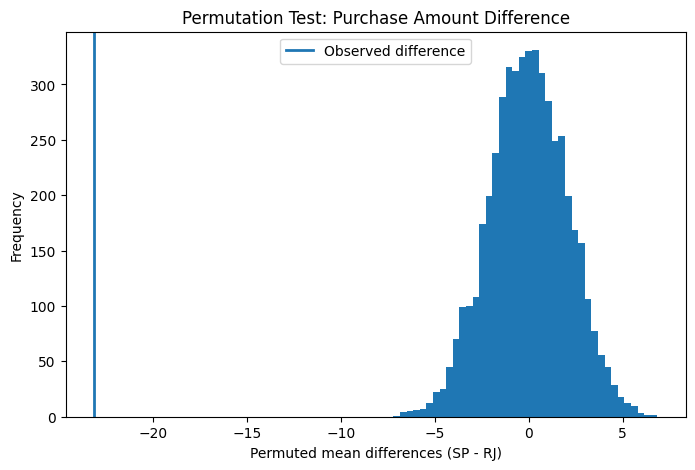

In [0]:
plt.figure(figsize=(8, 5))
plt.hist(perm_diffs, bins=40)
plt.axvline(observed_diff, linewidth=2, label="Observed difference")
plt.xlabel("Permuted mean differences (SP - RJ)")
plt.ylabel("Frequency")
plt.title("Permutation Test: Purchase Amount Difference")
plt.legend()
plt.show()

## 4. Delivery time and review score

Join reviews to orders with delivery dates and retain nonnegative delivery intervals. The unit is a joined review record; multiple reviews can give an order extra weight. Review scores are ordinal, and Pearson correlation is a descriptive linear summary. Association does not establish that delivery time causes the score.

In [0]:
reviews_df = read_olist("olist_order_reviews_dataset.csv")

delivery_review_df = (
    orders_df
    .join(reviews_df, on="order_id", how="inner")
    .filter(
        F.col("order_purchase_timestamp").isNotNull() &
        F.col("order_delivered_customer_date").isNotNull() &
        F.col("review_score").isNotNull()
    )
    .withColumn(
        "delivery_time_days",
        (
            F.unix_timestamp("order_delivered_customer_date") -
            F.unix_timestamp("order_purchase_timestamp")
        ) / 86400.0
    )
    .select("order_id", "delivery_time_days", "review_score")
    .filter(F.col("delivery_time_days") >= 0)
)

display(delivery_review_df.limit(10))

order_id,delivery_time_days,review_score
e481f51cbdc54678b7cc49136f2d6af7,8.436574074074073,4
53cdb2fc8bc7dce0b6741e2150273451,13.782037037037037,4
47770eb9100c2d0c44946d9cf07ec65d,9.394212962962962,5
949d5b44dbf5de918fe9c16f97b45f8a,13.20875,5
ad21c59c0840e6cb83a9ceb5573f8159,2.873877314814815,5
a4591c265e18cb1dcee52889e2d8acc3,16.54224537037037,4
6514b8ad8028c9f2cc2374ded245783f,9.989826388888888,5
76c6e866289321a7c93b82b54852dc33,9.818761574074074,1
e69bfb5eb88e0ed6a785585b27e16dbf,18.221851851851852,5
e6ce16cb79ec1d90b1da9085a6118aeb,12.6509375,1


In [0]:
from pyspark.sql.functions import col

delivery_review_df = delivery_review_df.withColumn(
    "delivery_time_days", col("delivery_time_days").cast("double")
).withColumn(
    "review_score", col("review_score").cast("double")
)

In [0]:
corr_value = delivery_review_df.stat.corr("delivery_time_days", "review_score")
print("Pearson correlation:", corr_value)

Pearson correlation: -0.33380409076684003


### Permutation assessment of negative association

Shuffle review scores across the fixed delivery times. The one-sided alternative is negative association. Exchangeability and independent records are assumptions; multiple reviews and repeated customers are limitations. This is exploratory evidence, not a causal test.

In [0]:
delivery_review_pd = delivery_review_df.select("delivery_time_days", "review_score").toPandas().dropna()
x = delivery_review_pd["delivery_time_days"].to_numpy()
y = delivery_review_pd["review_score"].to_numpy()

observed_r = np.corrcoef(x, y)[0, 1]

n_perm = N_PERMUTATIONS
perm_rs = np.empty(n_perm)

rng = np.random.default_rng(SEED)

for i in range(n_perm):
    perm_y = rng.permutation(y)
    perm_rs[i] = np.corrcoef(x, perm_y)[0, 1]

# one-sided p-value for negative correlation
extreme_count = np.count_nonzero(perm_rs <= observed_r)
perm_corr_p_value = (extreme_count + 1) / (n_perm + 1)

print("Observed Pearson correlation:", observed_r)
print("Permutation p-value:", perm_corr_p_value)

Observed Pearson correlation: -0.33380409076684237
Permutation p-value: 0.0001999600079984003


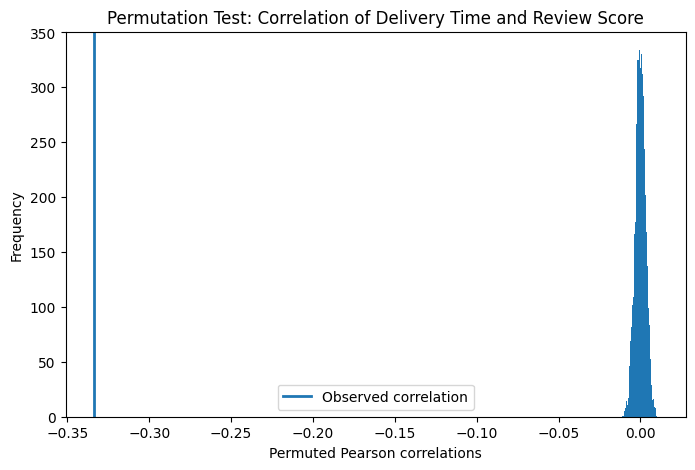

In [0]:
plt.figure(figsize=(8, 5))
plt.hist(perm_rs, bins=40)
plt.axvline(observed_r, linewidth=2, label="Observed correlation")
plt.xlabel("Permuted Pearson correlations")
plt.ylabel("Frequency")
plt.title("Permutation Test: Correlation of Delivery Time and Review Score")
plt.legend()
plt.show()

## Interpretation and next steps

São Paulo orders had a mean summed payment of 143.69, compared with 166.85 in Rio de Janeiro: a difference of −23.16 (SP − RJ). The Welch test and the permutation comparison both provide evidence of a difference under their respective assumptions.

Delivery duration and review score had a Pearson correlation of approximately −0.334. The one-sided permutation test returned p ≈ 0.0002, supporting a negative association under the exchangeability assumption. Longer delivery times were associated with lower review scores; this does not establish causation.

Geographic screening found 40 rows beyond the expanded rectangle. Among 1,000,134 rows retained after the median-coordinate screen, 576 (0.0576%) were more than 200 km from their ZIP-prefix median. Most retained rows were therefore within 200 km, but this threshold does not establish address accuracy.

Further work could use verified geographic boundaries, inspect duplicate reviews and repeated customers, separate canceled orders, assess missing delivery dates, quantify effect sizes and uncertainty, and model delivery delays relative to promised dates. Geographic cleaning here is a separate exploration; it is not applied to the payment or review analysis.
